# Lab 5 - 7.8.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Generate the model to classify the news documents as fake or not fake using
       Multinomial Naive Bayes classifier for the given dataset “fakenews”. It has
       the training and testing data separately. Analyze the performance of the
       training and testing data and visualize the results.

    2. Use the suitable Naive Bayes model to classify the raisin categories based
       on the input features given in the raisin dataset. Use the split of 80 and
       20 for training and testing the dataset. Analyze the performance and
       visualize the results.

    3. Generate the model to classify the subscription of term deposit using
       Logistic Regression for the given dataset “bankmarket.csv”. Use the
       following input features - 'age', 'duration', 'campaign', 'previous',
       'housing', 'loan' target feature as “y”. Use 70:15:15 (train, validation,
       test) split and analyze the performance of the data and visualize the
       results. Display the validation accuracy and test data accuracy.

### 1.

### Multinomial Naive Bayes - Fake news classification

#### Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
news_train_df = pd.read_csv('Lab 4-31.7.26/train.csv').drop(columns='Unnamed: 0')
news_test_df = pd.read_csv('Lab 4-31.7.26/test.csv').drop(columns='Unnamed: 0')

print(f"Train shape: {news_train_df.shape}, Test shape: {news_test_df.shape}")
news_train_df.head()

Train shape: (17090, 2), Test shape: (4228, 2)


,news,label
0,“Pennsylvania is under a court order to count ...,0
1,“Biden and Democrats have dismantled border se...,0
2,Katie Hobbs “has voted to double our gas tax. ...,1
3,Reuters reported that Nancy Pelosi bought 10 m...,0
4,"It's not true that ""the United States was buil...",0


#### Vectorize text

In [3]:
vectorizer = CountVectorizer(max_features=5000, stop_words='english')

X_train_news = vectorizer.fit_transform(news_train_df['news'])
X_test_news = vectorizer.transform(news_test_df['news'])

y_train_news = news_train_df['label']
y_test_news = news_test_df['label']

#### Train model

In [4]:
mnb_model = MultinomialNB()
mnb_model.fit(X_train_news, y_train_news)

y_train_pred_news = mnb_model.predict(X_train_news)
y_test_pred_news = mnb_model.predict(X_test_news)

#### Performance evaluation

In [5]:
mnb_train_accuracy = accuracy_score(y_train_news, y_train_pred_news)
mnb_test_accuracy = accuracy_score(y_test_news, y_test_pred_news)

print(f"Training Accuracy: {mnb_train_accuracy:.4f}")
print(f"Testing Accuracy: {mnb_test_accuracy:.4f}")
print()
print("Training Classification Report:")
print(classification_report(y_train_news, y_train_pred_news))
print("Testing Classification Report:")
print(classification_report(y_test_news, y_test_pred_news))

Training Accuracy: 0.7394
Testing Accuracy: 0.7266

Training Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.70      0.75      9746
           1       0.66      0.79      0.72      7344

    accuracy                           0.74     17090
   macro avg       0.74      0.75      0.74     17090
weighted avg       0.75      0.74      0.74     17090

Testing Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.69      0.74      2399
           1       0.65      0.78      0.71      1829

    accuracy                           0.73      4228
   macro avg       0.73      0.73      0.73      4228
weighted avg       0.74      0.73      0.73      4228



#### Visualize results

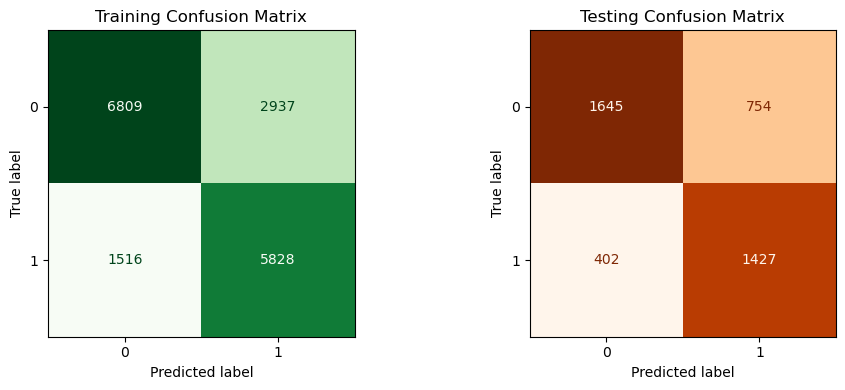

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_train = confusion_matrix(y_train_news, y_train_pred_news)
ConfusionMatrixDisplay(confusion_matrix=cm_train).plot(ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Training Confusion Matrix')

cm_test = confusion_matrix(y_test_news, y_test_pred_news)
ConfusionMatrixDisplay(confusion_matrix=cm_test).plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title('Testing Confusion Matrix')

plt.tight_layout()
plt.show()

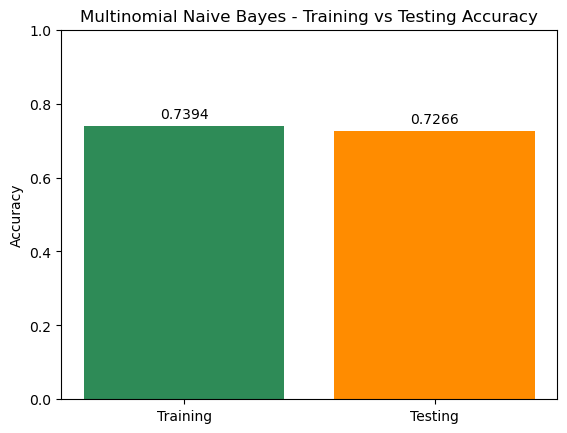

In [7]:
plt.bar(['Training', 'Testing'], [mnb_train_accuracy, mnb_test_accuracy], color=['seagreen', 'darkorange'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('Multinomial Naive Bayes - Training vs Testing Accuracy')
for i, acc in enumerate([mnb_train_accuracy, mnb_test_accuracy]):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center')
plt.show()

### 2.

### Naive Bayes - Raisin classification

#### Load dataset

In [8]:
raisin_df = pd.read_csv('Lab 3-24.7.26/Raisin.csv')
raisin_df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [9]:
raisin_df['Class'].value_counts()

Class
Kecimen    450
Besni      450
Name: count, dtype: int64

#### Features & target

In [10]:
X_raisin = raisin_df.drop(columns='Class')
y_raisin = raisin_df['Class']

#### Train-test split

In [11]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_raisin, y_raisin, test_size=0.2, random_state=1265, stratify=y_raisin
)

#### Train model

The raisin features (Area, MajorAxisLength, MinorAxisLength, Eccentricity, ConvexArea,
Extent, Perimeter) are all continuous, so Gaussian Naive Bayes is the suitable choice
since it models each feature as a normal distribution per class.

In [12]:
gnb_model = GaussianNB()
gnb_model.fit(X_train_r, y_train_r)

y_pred_r = gnb_model.predict(X_test_r)

#### Performance evaluation

In [13]:
gnb_accuracy = accuracy_score(y_test_r, y_pred_r)
print(f"Accuracy: {gnb_accuracy:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test_r, y_pred_r))

Accuracy: 0.8444

Classification Report:
              precision    recall  f1-score   support

       Besni       0.92      0.76      0.83        90
     Kecimen       0.79      0.93      0.86        90

    accuracy                           0.84       180
   macro avg       0.86      0.84      0.84       180
weighted avg       0.86      0.84      0.84       180



#### Visualize results

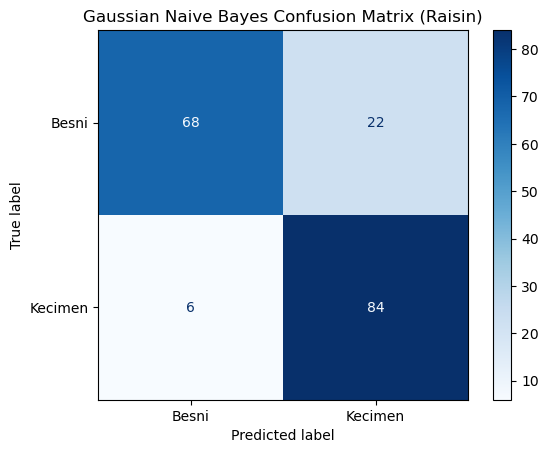

In [14]:
cm_r = confusion_matrix(y_test_r, y_pred_r, labels=gnb_model.classes_)
disp_r = ConfusionMatrixDisplay(confusion_matrix=cm_r, display_labels=gnb_model.classes_)
disp_r.plot(cmap='Blues')
plt.title('Gaussian Naive Bayes Confusion Matrix (Raisin)')
plt.show()

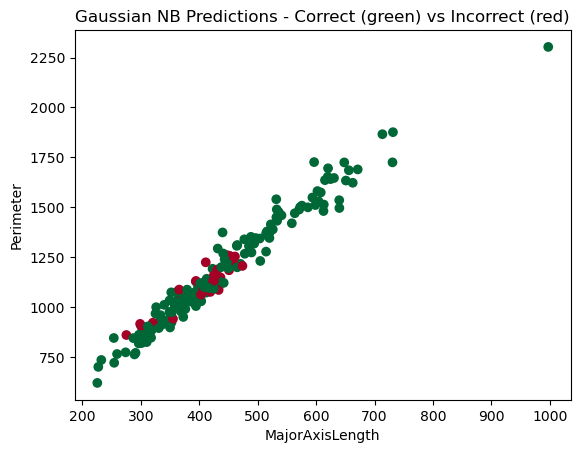

In [15]:
plt.scatter(X_test_r['MajorAxisLength'], X_test_r['Perimeter'], c=(y_test_r == y_pred_r), cmap='RdYlGn')
plt.xlabel('MajorAxisLength')
plt.ylabel('Perimeter')
plt.title('Gaussian NB Predictions - Correct (green) vs Incorrect (red)')
plt.show()

### 3.

### Logistic Regression - Term deposit subscription

#### Load dataset

In [16]:
bank_df = pd.read_csv('Lab 5-7.8.26/bankmarket.csv', sep=';')
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [17]:
bank_df['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

#### Select features

In [18]:
features = ['age', 'duration', 'campaign', 'previous', 'housing', 'loan']

X_bank = bank_df[features].copy()
y_bank = (bank_df['y'] == 'yes').astype(int)

#### Train:validation:test split (70:15:15)

In [19]:
X_train_b, X_temp_b, y_train_b, y_temp_b = train_test_split(
    X_bank, y_bank, test_size=0.3, random_state=1265, stratify=y_bank
)
X_val_b, X_test_b, y_val_b, y_test_b = train_test_split(
    X_temp_b, y_temp_b, test_size=0.5, random_state=1265, stratify=y_temp_b
)

print(f"Train: {len(X_train_b)}, Validation: {len(X_val_b)}, Test: {len(X_test_b)}")

Train: 28831, Validation: 6178, Test: 6179


#### Encode categorical features (fit on training data only)

The ordinal encoder for `housing`/`loan` is fit on `X_train_b` only, then reused
to transform the validation and test splits. Learning the category mapping from
the full dataset before splitting would let the encoder see the validation/test
rows in advance, which is a data leak even though, for this particular fixed
`yes`/`no`/`unknown` mapping, its practical effect on the reported accuracy is
usually negligible.

In [20]:
X_train_b = X_train_b.copy()
X_val_b = X_val_b.copy()
X_test_b = X_test_b.copy()

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_b[['housing', 'loan']] = encoder.fit_transform(X_train_b[['housing', 'loan']])
X_val_b[['housing', 'loan']] = encoder.transform(X_val_b[['housing', 'loan']])
X_test_b[['housing', 'loan']] = encoder.transform(X_test_b[['housing', 'loan']])

#### Feature scaling

In [21]:
scaler_b = StandardScaler()
X_train_b_scaled = scaler_b.fit_transform(X_train_b)
X_val_b_scaled = scaler_b.transform(X_val_b)
X_test_b_scaled = scaler_b.transform(X_test_b)

#### Train model

In [22]:
log_reg = LogisticRegression(max_iter=1000, random_state=1265)
log_reg.fit(X_train_b_scaled, y_train_b)

y_val_pred_b = log_reg.predict(X_val_b_scaled)
y_test_pred_b = log_reg.predict(X_test_b_scaled)

#### Performance evaluation

In [23]:
val_accuracy = accuracy_score(y_val_b, y_val_pred_b)
test_accuracy = accuracy_score(y_test_b, y_test_pred_b)

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print()
print("Validation Classification Report:")
print(classification_report(y_val_b, y_val_pred_b))
print("Test Classification Report:")
print(classification_report(y_test_b, y_test_pred_b))

Validation Accuracy: 0.8974
Test Accuracy: 0.8985

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      5482
           1       0.62      0.23      0.33       696

    accuracy                           0.90      6178
   macro avg       0.77      0.60      0.64      6178
weighted avg       0.88      0.90      0.88      6178

Test Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      5483
           1       0.64      0.23      0.34       696

    accuracy                           0.90      6179
   macro avg       0.77      0.61      0.64      6179
weighted avg       0.88      0.90      0.88      6179



#### Visualize results

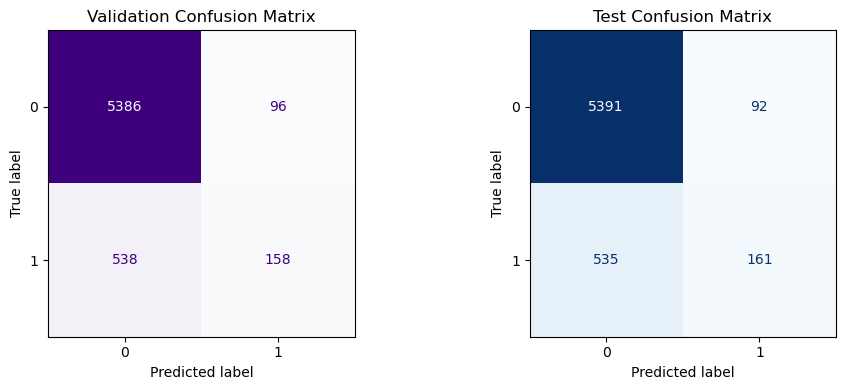

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_val = confusion_matrix(y_val_b, y_val_pred_b)
ConfusionMatrixDisplay(confusion_matrix=cm_val).plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title('Validation Confusion Matrix')

cm_test_b = confusion_matrix(y_test_b, y_test_pred_b)
ConfusionMatrixDisplay(confusion_matrix=cm_test_b).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Test Confusion Matrix')

plt.tight_layout()
plt.show()

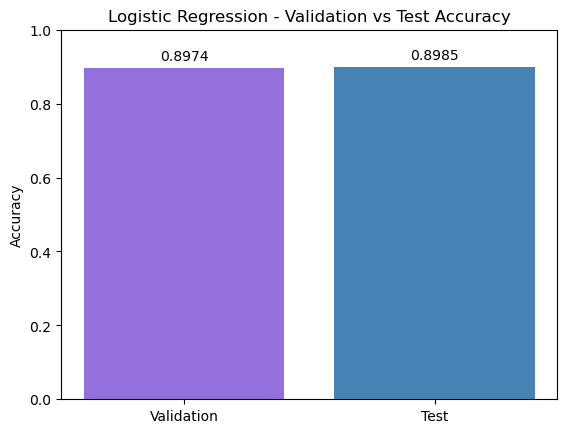

In [25]:
plt.bar(['Validation', 'Test'], [val_accuracy, test_accuracy], color=['mediumpurple', 'steelblue'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('Logistic Regression - Validation vs Test Accuracy')
for i, acc in enumerate([val_accuracy, test_accuracy]):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center')
plt.show()